Avokadó árak előrejelzése


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("avocado.csv")
df.head(10)

,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany
5,5,2015-11-22,1.26,55979.78,1184.27,48067.99,43.61,6683.91,6556.47,127.44,0.0,conventional,2015,Albany
6,6,2015-11-15,0.99,83453.76,1368.92,73672.72,93.26,8318.86,8196.81,122.05,0.0,conventional,2015,Albany
7,7,2015-11-08,0.98,109428.33,703.75,101815.36,80.00,6829.22,6266.85,562.37,0.0,conventional,2015,Albany
8,8,2015-11-01,1.02,99811.42,1022.15,87315.57,85.34,11388.36,11104.53,283.83,0.0,conventional,2015,Albany
9,9,2015-10-25,1.07,74338.76,842.40,64757.44,113.00,8625.92,8061.47,564.45,0.0,conventional,2015,Albany


In [3]:
print("Sorok és oszlopok száma:", df.shape)
print("\nOszlopok nevei:", df.columns.tolist())

print("\nTermesztési típusok eloszlása:")
print(df['type'].value_counts())

Sorok és oszlopok száma: (18249, 14)

Oszlopok nevei: ['Unnamed: 0', 'Date', 'AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags', 'XLarge Bags', 'type', 'year', 'region']

Termesztési típusok eloszlása:
type
conventional    9126
organic         9123
Name: count, dtype: int64


Feltáró adatelemzés – EDA

### 1. Adathalmaz és a feladat meghatározása

**1. Az adathalmaz eredete, célja és tartalma:**
A választott adathalmaz a Hass Avocado Board (HAB) hivatalos kiskereskedelmi eladási statisztikáiból származik (`avocado.csv`). Az adathalmaz az Egyesült Államok különböző régióiban 2015 és 2018 között értékesített avokádók heti árait és eladási mennyiségeit rögzíti.

**2. Méret és legfontosabb változók:**
Az adathalmaz **18 249 rekordot (sort)** és **14 oszlopot (változót)** tartalmaz. A legfontosabb változók:
- `Date` és `year`: A mérés dátuma és éve (2015–2018).
- `AveragePrice`: Egy darab avokádó átlagos eladási ára dollárban (USD).
- `Total Volume`: Az adott héten eladott avokádók összesített mennyisége.
- `4046`, `4225`, `4770`: Különböző méretkódú (PLU) avokádók eladott mennyisége (kicsi, nagy, extra nagy).
- `Total Bags`, `Small Bags`, `Large Bags`, `XLarge Bags`: A csomagolva értékesített avokádók mennyisége méret szerint.
- `type`: Termesztési típus (`conventional` = hagyományos, `organic` = bio).
- `region`: Az értékesítés földrajzi régiója (54 különböző amerikai város/régió).

**3. A megoldandó gépi tanulási probléma:**
A feladat egy **regressziós (regression)** probléma megoldása. A cél egy olyan gépi tanulási modell betanítása, amely az eladási mennyiségek, az év, a régió és a termesztési típus alapján képes minél pontosabban előrejelezni az avokádó várható átlagárát (`AveragePrice`). Az adathalmaz kiválóan alkalmas erre, mivel tiszta, jól strukturált numerikus és kategorikus jellemzőket tartalmaz.

**4. Célváltozó és bemeneti jellemzők:**
- **Célváltozó (target - $y$):** Az `AveragePrice` (átlagár) folytonos numerikus változó.
- **Bemeneti jellemzők (features - $X$):** Az eladási mennyiségek (`Total Volume`, PLU kódok, csomagolási adatok), a termesztési típus (`type`), valamint az év (`year`). A felesleges indexoszlopot (`Unnamed: 0`) az előfeldolgozás során eltávolítom.

Adattípusok:
 Unnamed: 0        int64
Date                str
AveragePrice    float64
Total Volume    float64
4046            float64
4225            float64
4770            float64
Total Bags      float64
Small Bags      float64
Large Bags      float64
XLarge Bags     float64
type                str
year              int64
region              str
dtype: object

Alapvető statisztikai mutatók:
       AveragePrice  Total Volume    Total Bags          year
count  18249.000000  1.824900e+04  1.824900e+04  18249.000000
mean       1.405978  8.506440e+05  2.396392e+05   2016.147899
std        0.402677  3.453545e+06  9.862424e+05      0.939938
min        0.440000  8.456000e+01  0.000000e+00   2015.000000
25%        1.100000  1.083858e+04  5.088640e+03   2015.000000
50%        1.370000  1.073768e+05  3.974383e+04   2016.000000
75%        1.660000  4.329623e+05  1.107834e+05   2017.000000
max        3.250000  6.250565e+07  1.937313e+07   2018.000000

Hiányzó értékek száma oszloponként:
 Unnamed:

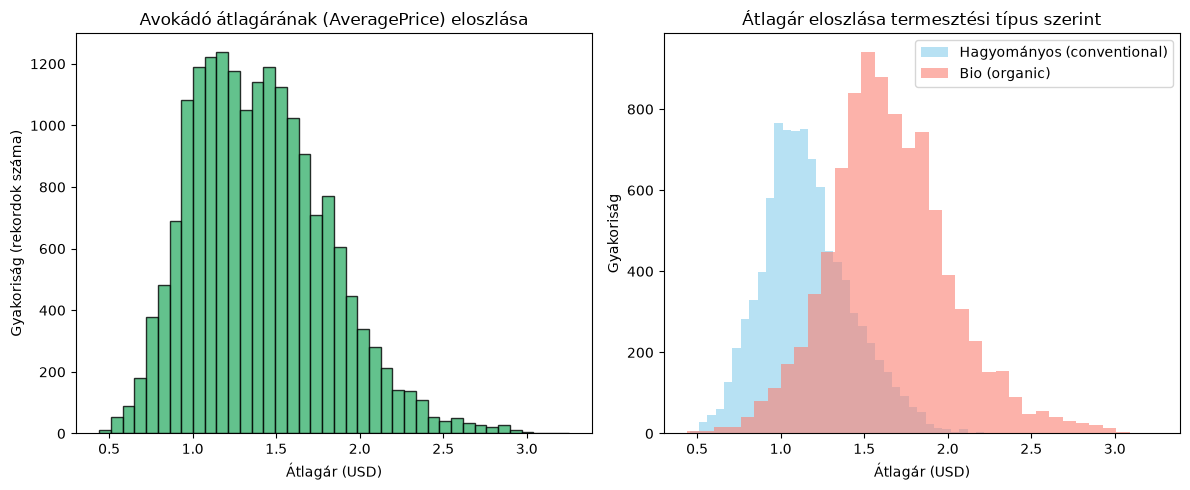

In [4]:
# 1. Oszlopok adattípusai és alapvető statisztikák
print("Adattípusok:\n", df.dtypes)
print("\nAlapvető statisztikai mutatók:")
print(df[['AveragePrice', 'Total Volume', 'Total Bags', 'year']].describe())

# 2. Adatminőség ellenőrzése: hiányzó értékek és duplikátumok
print("\nHiányzó értékek száma oszloponként:\n", df.isnull().sum())
print("\nDuplikált sorok száma:", df.duplicated().sum())

# 3. Vizualizációk (2 db diagram egymás mellett)
plt.figure(figsize=(12, 5))

# 1. ábra: A célváltozó (AveragePrice) eloszlása
plt.subplot(1, 2, 1)
plt.hist(df['AveragePrice'], bins=40, color='mediumseagreen', edgecolor='black', alpha=0.8)
plt.title('Avokádó átlagárának (AveragePrice) eloszlása')
plt.xlabel('Átlagár (USD)')
plt.ylabel('Gyakoriság (rekordok száma)')

# 2. ábra: Hagyományos vs. Bio (Organic) avokádó árai
plt.subplot(1, 2, 2)
plt.hist(df[df['type'] == 'conventional']['AveragePrice'], bins=35, alpha=0.6, label='Hagyományos (conventional)', color='skyblue')
plt.hist(df[df['type'] == 'organic']['AveragePrice'], bins=35, alpha=0.6, label='Bio (organic)', color='salmon')
plt.title('Átlagár eloszlása termesztési típus szerint')
plt.xlabel('Átlagár (USD)')
plt.ylabel('Gyakoriság')
plt.legend()

plt.tight_layout()
plt.show()